# Smart Fan Controller
Fuzzy Logic and Genetic Programming PBL

L.D. College of Engineering, Ahmedabad. Chemical Engineering, Division A.

- Kirtan Siddhapura: 240280105071
- Mahesh Bhaliya: 240280105005
- Manav Chauhan: 240280105008
- Haresh Raval: 240280105065

Software simulation. Rules and thresholds are illustrative.

## Setup
Install NumPy >=2.0 and matplotlib >=3.8 in your notebook environment if needed. The inference works without matplotlib. GP uses only NumPy and Python standard libraries.

In [1]:
"""Mamdani smart fan simulation + optional tree genetic programming experiment.
Run: python smart_fan.py --output results
Requires numpy; matplotlib enables plots. No hardware or measured comfort data.
"""
import argparse, csv, json, random, copy
from pathlib import Path
import numpy as np

TEMP = [(15,15,27),(20,28,36),(29,40,40)]
HUM = [(20,20,55),(35,60,85),(65,90,90)]
SPEED = [(0,0,50),(25,50,75),(50,100,100)]
RULES = np.array([[0,0,1],[0,1,2],[2,2,2]])
NAMES = ['Low','Medium','High']

def triangular(x, abc):
    x = np.asarray(x, dtype=float)
    a,b,c = abc
    left = np.ones_like(x) if a == b else (x-a)/(b-a)
    right = np.ones_like(x) if b == c else (c-x)/(c-b)
    return np.where((x<a)|(x>c),0,np.maximum(0,np.minimum(1,np.minimum(left,right))))

def fan_speed(temperature, humidity, details=False):
    t,h = float(temperature),float(humidity)
    if not np.isfinite(t+h) or not (15 <= t <= 40 and 20 <= h <= 90):
        raise ValueError('Use finite temperature 15..40 C and humidity 20..90 %RH')
    mt=np.array([float(triangular(t,m)) for m in TEMP])
    mh=np.array([float(triangular(h,m)) for m in HUM])
    strengths=np.minimum(mt[:,None],mh[None,:])
    z=np.linspace(0,100,1001)
    agg=np.zeros_like(z)
    for i in range(3):
        for j in range(3):
            agg=np.maximum(agg,np.minimum(strengths[i,j],triangular(z,SPEED[RULES[i,j]])))
    # Centroid of the sampled aggregate; 0.1 percentage-point output resolution.
    area=np.trapezoid(agg,z)
    if area<=0: raise RuntimeError('No active fuzzy rule')
    result=float(np.trapezoid(z*agg,z)/area)
    return (result,mt,mh,strengths,z,agg) if details else result

# GP individuals are expression trees, rather than numeric GA chromosomes.
def generate(rng, depth=3):
    if depth==0 or rng.random()<0.3: return rng.choice(['t','h',0.25,0.5,1.0,-0.5])
    return (rng.choice(['+','-','*','max','min']),generate(rng,depth-1),generate(rng,depth-1))
def evaluate(tree,t,h):
    if tree=='t' if isinstance(tree,str) else False: return t
    if tree=='h' if isinstance(tree,str) else False: return h
    if not isinstance(tree,tuple): return np.full_like(t,float(tree))
    op,a,b=tree; a=evaluate(a,t,h); b=evaluate(b,t,h)
    return {'+':lambda:a+b,'-':lambda:a-b,'*':lambda:a*b,'max':lambda:np.maximum(a,b),'min':lambda:np.minimum(a,b)}[op]()
def paths(tree):
    return [()] + ([ (i,)+p for i in [1,2] for p in paths(tree[i])] if isinstance(tree,tuple) else [])
def subtree(tree,path):
    for i in path: tree=tree[i]
    return tree
def replace(tree,path,new):
    if not path:return new
    vals=list(tree); vals[path[0]]=replace(vals[path[0]],path[1:],new); return tuple(vals)
def depth(tree):return 0 if not isinstance(tree,tuple) else 1+max(depth(tree[1]),depth(tree[2]))
def expression(tree):
    if not isinstance(tree,tuple):return str(tree)
    op,a,b=tree
    return f'{op}({expression(a)}, {expression(b)})' if op in ['min','max'] else f'({expression(a)} {op} {expression(b)})'
def gp_experiment():
    rng=random.Random(71)
    grid=np.array([(t,h,fan_speed(t,h)/100) for t in np.linspace(15,40,11) for h in np.linspace(20,90,11)])
    idx=list(range(len(grid)));rng.shuffle(idx)
    train,test=grid[idx[:85]],grid[idx[85:]]
    def predict(tree,data):return np.clip(evaluate(tree,(data[:,0]-15)/25,(data[:,1]-20)/70),0,1)
    def score(tree):return float(np.mean((predict(tree,train)-train[:,2])**2))+0.00005*len(paths(tree))
    pop=[generate(rng) for _ in range(100)];history=[]
    for generation in range(41):
        pop.sort(key=score);history.append(float(np.sqrt(np.mean((predict(pop[0],train)-train[:,2])**2))*100))
        if generation==40:break
        def select():return min(rng.sample(pop,3),key=score)
        new=pop[:2]
        while len(new)<100:
            a,b=select(),select()
            child=replace(a,rng.choice(paths(a)),subtree(b,rng.choice(paths(b)))) if rng.random()<0.8 else a
            if rng.random()<0.2:child=replace(child,rng.choice(paths(child)),generate(rng,2))
            new.append(child if depth(child)<=6 else a)
        pop=new
    best=pop[0]
    return dict(seed=71,population=100,generations=40,train_count=85,test_count=36,expression=expression(best),train_rmse=history[-1],test_rmse=float(np.sqrt(np.mean((predict(best,test)-test[:,2])**2))*100),history=history)

def main(output='results'):
    out=Path(output);out.mkdir(parents=True,exist_ok=True)
    examples=[(15,20),(22,40),(28,60),(30,80),(35,50),(40,90)]
    rows=[dict(temperature_C=t,humidity_RH=h,speed_percent=round(fan_speed(t,h),3)) for t,h in examples]
    with (out/'examples.csv').open('w',newline='') as f:
        w=csv.DictWriter(f,fieldnames=rows[0]);w.writeheader();w.writerows(rows)
    gp=gp_experiment();(out/'gp_results.json').write_text(json.dumps(gp,indent=2))
    # Coverage, bounds, invalid input and deterministic GP checks.
    grid=np.array([[fan_speed(t,h) for h in np.linspace(20,90,29)] for t in np.linspace(15,40,51)])
    assert np.isfinite(grid).all() and ((grid>=0)&(grid<=100)).all()
    for t,h in [(14,50),(25,91),(float('nan'),50)]:
        try:fan_speed(t,h)
        except ValueError:pass
        else:raise AssertionError('Invalid input accepted')
    metrics={'grid_points':grid.size,'minimum':float(grid.min()),'maximum':float(grid.max()),'largest_temperature_drop':float(min(0,np.diff(grid,axis=0).min())),'largest_humidity_drop':float(min(0,np.diff(grid,axis=1).min()))}
    (out/'validation.json').write_text(json.dumps(metrics,indent=2))
    print(json.dumps({'examples':rows,'GP':gp,'validation':metrics},indent=2))
    try:import matplotlib.pyplot as plt
    except ImportError:
        print('Install matplotlib to generate plots. Numeric results are complete.');return
    plt.rcParams.update({'font.size':12,'axes.spines.top':False,'axes.spines.right':False})
    fig,axs=plt.subplots(1,3,figsize=(13,3.8))
    for ax,sets,ran,label in zip(axs,[TEMP,HUM,SPEED],[(15,40),(20,90),(0,100)],['Temperature (C)','Humidity (%RH)','Fan command (%)']):
        x=np.linspace(*ran,501)
        for name,m in zip(NAMES,sets):ax.plot(x,triangular(x,m),label=name,lw=2.5)
        ax.set(xlabel=label,ylabel='Membership',ylim=(-.05,1.1));ax.legend(fontsize=9)
    fig.tight_layout();fig.savefig(out/'membership.png',dpi=160);plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,4.5))
    im=ax.imshow(grid,origin='lower',extent=[20,90,15,40],aspect='auto',vmin=0,vmax=100,cmap='viridis')
    ax.set(xlabel='Humidity (%RH)',ylabel='Temperature (C)',title='Mamdani fan command');fig.colorbar(im,ax=ax,label='Speed (%)');fig.tight_layout();fig.savefig(out/'surface.png',dpi=160);plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,4.5))
    ts=np.linspace(15,40,251)
    for h in [30,60,85]:ax.plot(ts,[fan_speed(t,h) for t in ts],label=f'{h}% RH')
    ax.set(xlabel='Temperature (C)',ylabel='Fan command (%)',ylim=(0,100));ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig(out/'response.png',dpi=160);plt.close(fig)
    result,mt,mh,strength,z,agg=fan_speed(30,80,True)
    fig,ax=plt.subplots(figsize=(7,4));ax.fill_between(z,agg,alpha=.4);ax.axvline(result,color='crimson',label=f'Centroid = {result:.2f}%');ax.set(xlabel='Fan command (%)',ylabel='Aggregated membership');ax.legend();fig.tight_layout();fig.savefig(out/'centroid.png',dpi=160);plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,4));ax.plot(gp['history']);ax.set(xlabel='Generation',ylabel='Training RMSE (percentage points)',title='GP learns simulated fuzzy outputs');fig.tight_layout();fig.savefig(out/'gp_history.png',dpi=160);plt.close(fig)
    return rows,gp,metrics



## Reproduce results
The output directory is created in the current working directory. The controller uses min AND, max aggregation, and a sampled centroid. The GP labels come from the fuzzy controller.

In [2]:
result = main('results')

{
  "examples": [
    {
      "temperature_C": "15",
      "humidity_RH": "20",
      "speed_percent": "16.667"
    },
    {
      "temperature_C": "22",
      "humidity_RH": "40",
      "speed_percent": "29.848"
    },
    {
      "temperature_C": "28",
      "humidity_RH": "60",
      "speed_percent": "50.0"
    },
    {
      "temperature_C": "30",
      "humidity_RH": "80",
      "speed_percent": "73.113"
    },
    {
      "temperature_C": "35",
      "humidity_RH": "50",
      "speed_percent": "67.328"
    },
    {
      "temperature_C": "40",
      "humidity_RH": "90",
      "speed_percent": "83.333"
    }
  ],
  "GP": {
    "seed": 71,
    "population": 100,
    "generations": 40,
    "train_count": 85,
    "test_count": 36,
    "expression": "max(max(((h * 0.25) - (0.25 - t)), (-0.5 + (((0.25 * t) - (0.25 - 0.25)) + h))), max(0.25, -0.5))",
    "train_rmse": 9.214583783326166,
    "test_rmse": 9.430971148904572,
    "history": [
      15.226494970644442,
      15.2264949706444

## Inspect the plots
Local decreases exist in the Mamdani surface. No hardware energy or comfort data are used.

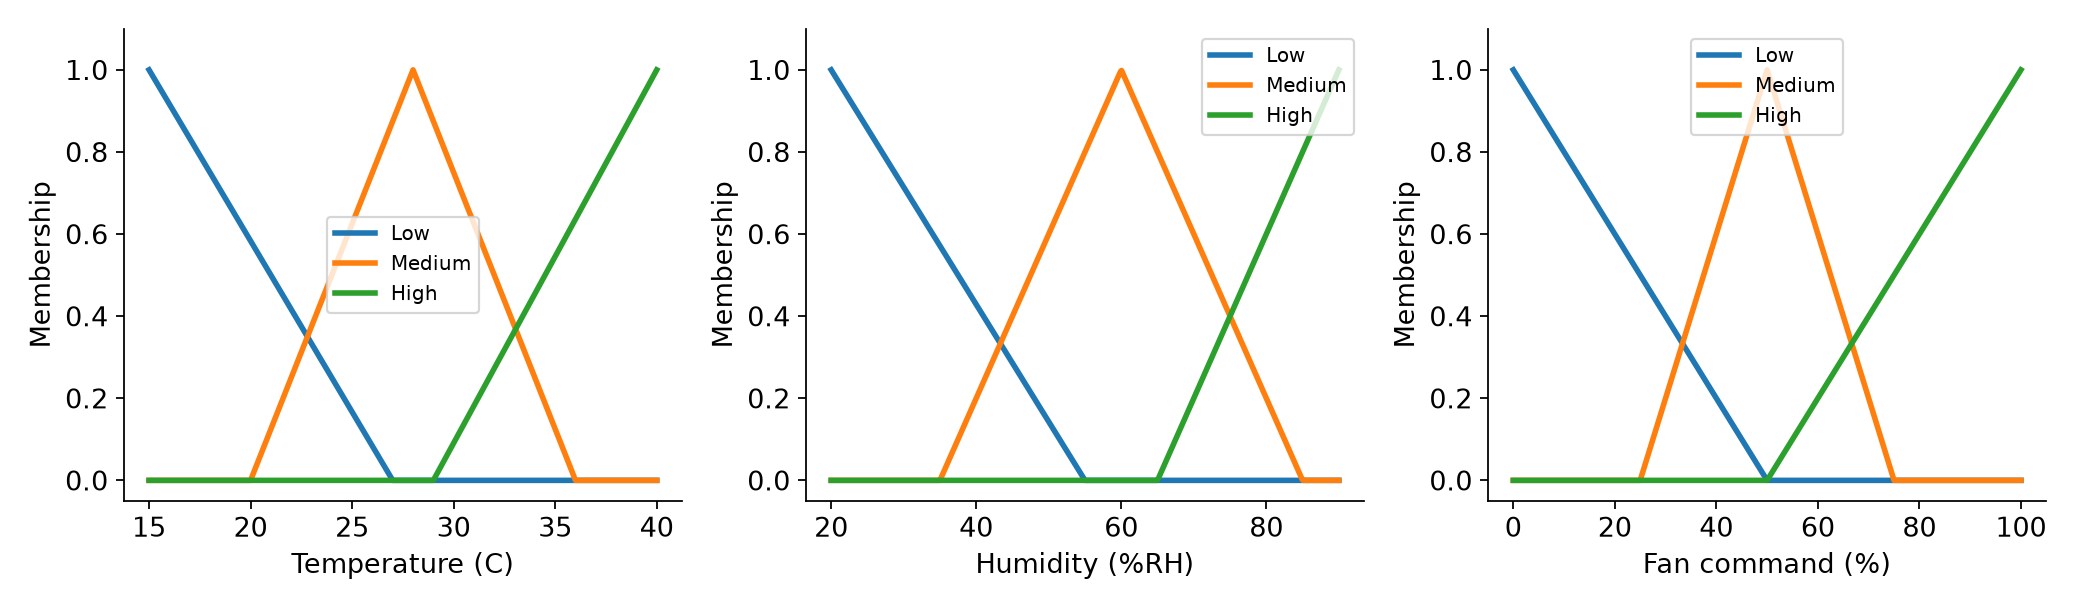

In [6]:
from IPython.display import Image, display
display(Image(filename='results/membership.png'))

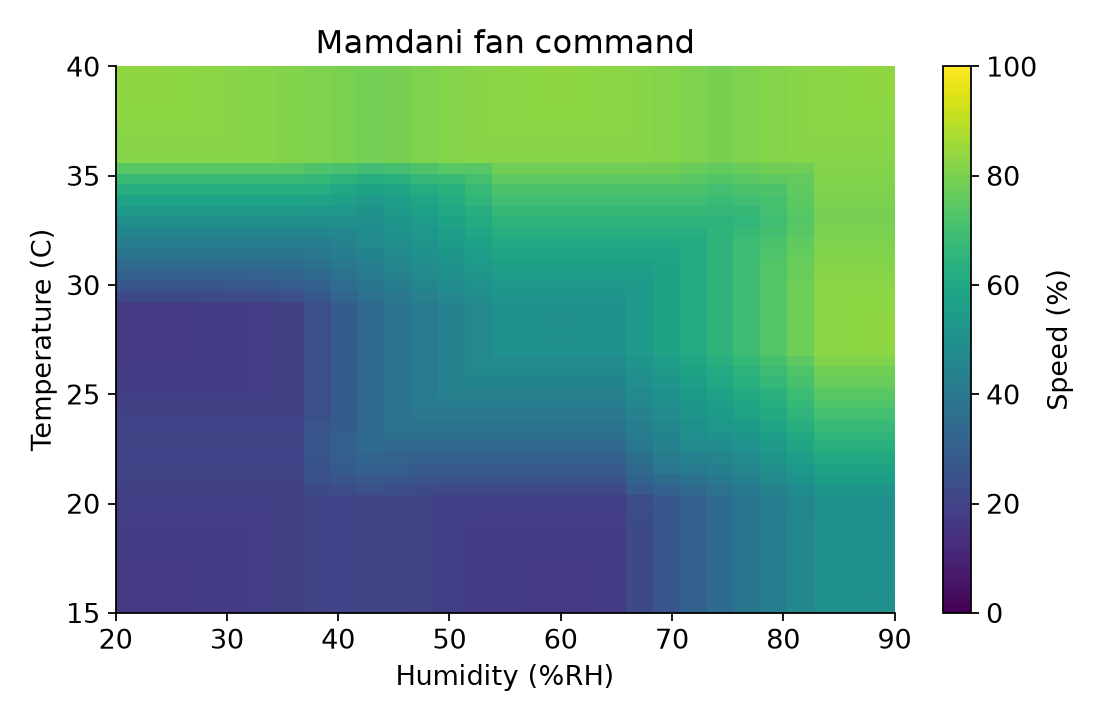

In [7]:
from IPython.display import Image, display
display(Image(filename='results/surface.png'))

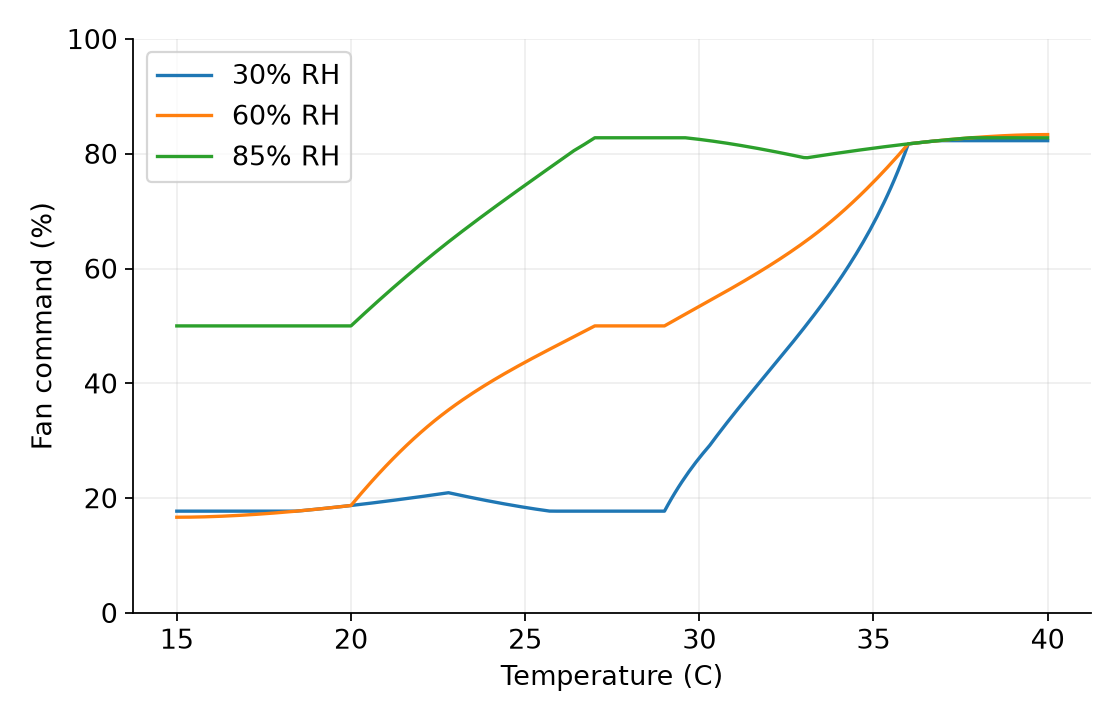

In [8]:
from IPython.display import Image, display
display(Image(filename='results/response.png'))

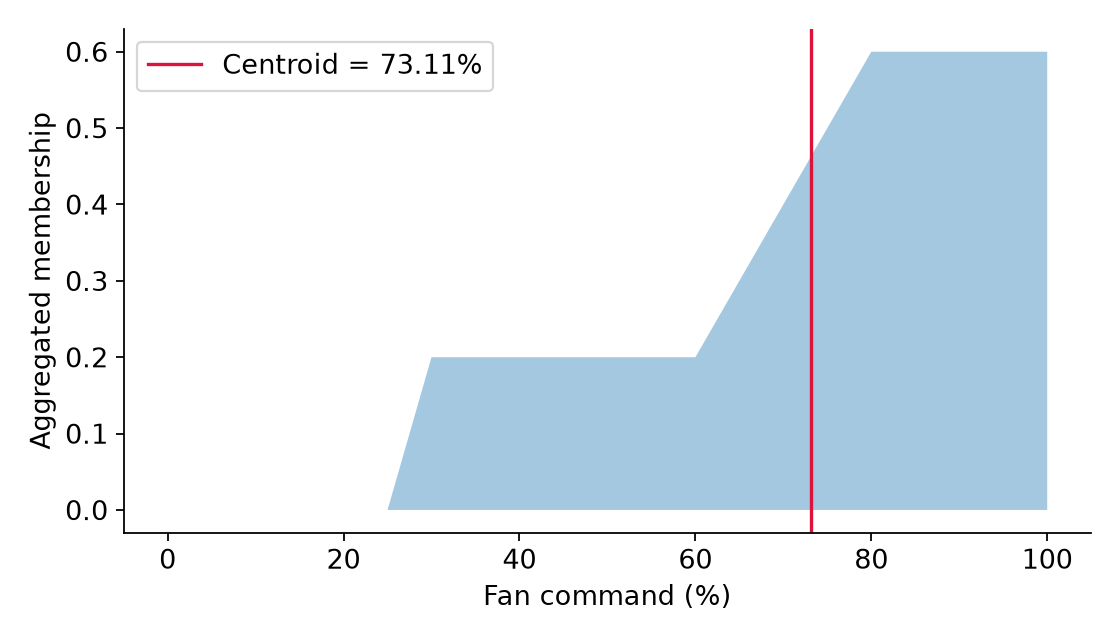

In [9]:
from IPython.display import Image, display
display(Image(filename='results/centroid.png'))

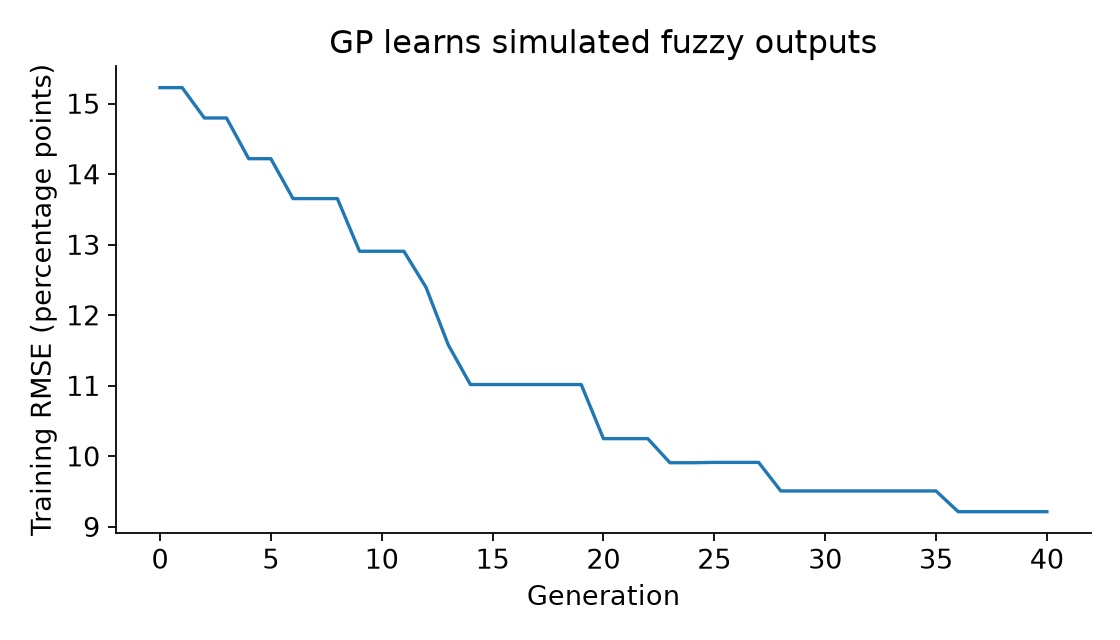

In [10]:
from IPython.display import Image, display
display(Image(filename='results/gp_history.png'))

## Interpretation
The output ranges from about 16.67 to 83.33 percent. GP held-out RMSE is 9.431 percentage points on simulated fuzzy labels. Inputs outside the declared domains raise ValueError. See report for full rules and limitations.